#PROJECT 10 : Overfitting and Underfitting Analysis

1. Import libraries and loading dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)

# Load Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("Classes:", iris.target_names)
print("Features:", iris.feature_names)

Dataset shape: (150, 4)
Classes: ['setosa' 'versicolor' 'virginica']
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


2. Spiltting the dataset and preprocessing

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


3. Build three neural network architectures

In [3]:

def build_model(architecture):
    model = Sequential()
    model.add(Input(shape=(4,)))

    for neurons in architecture:
        model.add(Dense(neurons, activation="relu"))

    model.add(Dense(3, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Different model complexities
architectures = {
    "Simple (Underfitting candidate)": [1],
    "Moderate (Balanced model)": [16, 8],
    "Complex (Overfitting candidate)": [128, 128, 64]
}

models = {}

for name, architecture in architectures.items():
    models[name] = build_model(architecture)

    print(f"\n{name}")
    models[name].summary()



Simple (Underfitting candidate)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             5 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11 (44.00 B)

 Trainable params: 11 (44.00 B)

...

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 128)            │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,603 (100.01 KB)

 Trainable params: 25,603 (100.01 KB)

 Non-trainable params: 0 (0.00 B)

4. Training All Neural network models

In [4]:

histories = {}

for name, model in models.items():
    print(f"\nTraining {name}...")

    histories[name] = model.fit(
        X_train,
        y_train_cat,
        epochs=300,
        batch_size=8,
        validation_split=0.2,
        shuffle=True,
        verbose=0
    )

print("Training completed for all models.")



Training Simple (Underfitting candidate)...

Training Moderate (Balanced model)...

Training Complex (Overfitting candidate)...
Training completed for all models.


5. Comparing training and testing performance

In [5]:

results = []

for name, model in models.items():
    train_loss, train_acc = model.evaluate(
        X_train, y_train_cat, verbose=0
    )

    test_loss, test_acc = model.evaluate(
        X_test, y_test_cat, verbose=0
    )

    accuracy_gap = (train_acc - test_acc) * 100

    # Classify fitting using performance indicators
    if train_acc < 0.85 and test_acc < 0.85:
        fitting = "Underfitting"
    elif accuracy_gap > 10 and train_acc > test_acc:
        fitting = "Overfitting"
    else:
        fitting = "Appropriate / Check losses"

    results.append({
        "Model": name,
        "Train Accuracy (%)": round(train_acc * 100, 2),
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Train Loss": round(train_loss, 4),
        "Test Loss": round(test_loss, 4),
        "Accuracy Gap (%)": round(accuracy_gap, 2),
        "Fitting Analysis": fitting
    })

results_df = pd.DataFrame(results)

print("MODEL PERFORMANCE COMPARISON")
print(results_df.to_string(index=False))

print("\nBEST MODEL BASED ON TEST ACCURACY:")
best_model = results_df.loc[
    results_df["Test Accuracy (%)"].idxmax()
]
print(best_model.to_string())


MODEL PERFORMANCE COMPARISON
                          Model  Train Accuracy (%)  Test Accuracy (%)  Train Loss  Test Loss  Accuracy Gap (%)           Fitting Analysis
Simple (Underfitting candidate)               68.33              66.67      0.4840     0.4833              1.67               Underfitting
      Moderate (Balanced model)              100.00              96.67      0.0190     0.0925              3.33 Appropriate / Check losses
Complex (Overfitting candidate)              100.00              93.33      0.0001     0.4169              6.67 Appropriate / Check losses

BEST MODEL BASED ON TEST ACCURACY:
Model                  Moderate (Balanced model)
Train Accuracy (%)                         100.0
Test Accuracy (%)                          96.67
Train Loss                                 0.019
Test Loss                                 0.0925
Accuracy Gap (%)                            3.33
Fitting Analysis      Appropriate / Check losses


6. Plotting Training Accuracy and loss

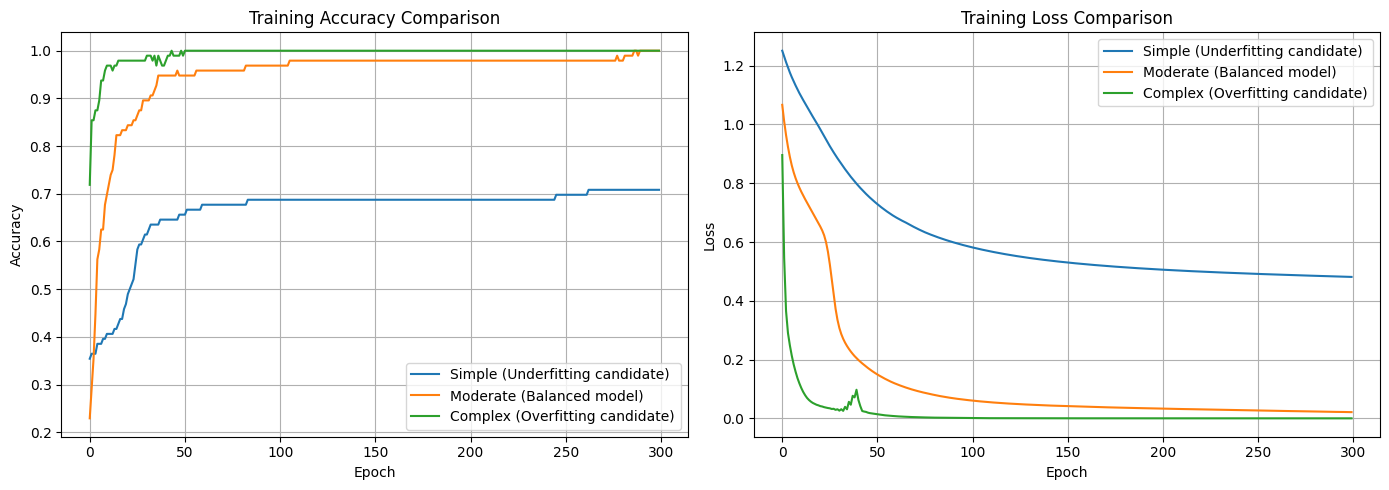

In [6]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for name, history in histories.items():
    # Accuracy curves
    axes[0].plot(
        history.history["accuracy"],
        label=f"{name} - Training"
    )
    axes[0].plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=f"{name} - Validation"
    )

    # Loss curves
    axes[1].plot(
        history.history["loss"],
        label=f"{name} - Training"
    )
    axes[1].plot(
        history.history["val_loss"],
        linestyle="--",
        label=f"{name} - Validation"
    )

axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=8)
axes[0].grid(True)

axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=8)
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [7]:

print("OVERFITTING AND UNDERFITTING ANALYSIS")
print("=" * 50)

for _, row in results_df.iterrows():
    print(f"\nModel: {row['Model']}")
    print(f"Training Accuracy: {row['Train Accuracy (%)']}%")
    print(f"Testing Accuracy: {row['Test Accuracy (%)']}%")
    print(f"Accuracy Gap: {row['Accuracy Gap (%)']}%")
    print(f"Initial Assessment: {row['Fitting Analysis']}")

print("\nIMPROVEMENT METHODS")
print("1. Underfitting: Increase model capacity or train longer.")
print("2. Overfitting: Use dropout, L2 regularization, or early stopping.")
print("3. Appropriate fitting: Keep the model with strong test performance.")
print("4. Generalization: Compare training, validation, and test performance.")


OVERFITTING AND UNDERFITTING ANALYSIS

Model: Simple (Underfitting candidate)
Training Accuracy: 68.33%
Testing Accuracy: 66.67%
Accuracy Gap: 1.67%
Initial Assessment: Underfitting

Model: Moderate (Balanced model)
Training Accuracy: 100.0%
Testing Accuracy: 96.67%
Accuracy Gap: 3.33%
Initial Assessment: Appropriate / Check losses

Model: Complex (Overfitting candidate)
Training Accuracy: 100.0%
Testing Accuracy: 93.33%
Accuracy Gap: 6.67%
Initial Assessment: Appropriate / Check losses

IMPROVEMENT METHODS
1. Underfitting: Increase model capacity or train longer.
2. Overfitting: Use dropout, L2 regularization, or early stopping.
3. Appropriate fitting: Keep the model with strong test performance.
4. Generalization: Compare training, validation, and test performance.


### Conclusion

In this project, three neural network architectures with different levels of complexity were developed using the Iris dataset to study underfitting, appropriate fitting, and overfitting.

All models used the same training and testing split to ensure a fair comparison. Their performance was evaluated using training accuracy, testing accuracy, training loss, testing loss, and validation learning curves.

The simple model was investigated as a potential example of underfitting, the moderate model as a balanced model, and the complex model as a potential example of overfitting. The actual results and learning curves were used to assess these patterns.

Underfitting can be addressed by increasing model capacity or training duration. Overfitting can be reduced through dropout, L2 regularization, and early stopping. An appropriate model should achieve strong generalization on unseen data rather than simply maximizing training accuracy.

This experiment demonstrates the importance of selecting a suitable neural network architecture for classification tasks.